# Titanic Logistic Regression — End-to-End

### Includes
- Data loading from the seborn titanic dataset
- Missing-value treatment
- Categorical-variable encoding
- Train/Test split
- Logistic Regression
- Coefficients and intercept
- 5-Fold Stratified Cross-Validation
- Fold-wise accuracy and mean CV accuracy
- Test-set predictions and probabilities
- Confusion Matrix
- Accuracy, Precision, Recall and F1 Score
- ROC Curve
- AUC
- Cross-validated ROC-AUC
- Complete Excel export with separate worksheets

## Model Evaluation Logic

The workflow follows this sequence:

**Raw Titanic data → preprocessing → train/test split → Logistic Regression → K-Fold CV → final test prediction → ROC/AUC → Excel export**

### Why use probability for ROC/AUC?

`model.predict()` gives the final class (`0` or `1`).

`model.predict_proba()` gives the probability of belonging to the positive class. ROC/AUC uses these probabilities at different classification thresholds.

### Why Stratified K-Fold?

Because this is a classification problem, **StratifiedKFold** keeps the proportion of survivors and non-survivors approximately similar in every fold.



In [200]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split,cross_validate,StratifiedKFold
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)


In [201]:
#Read Raw Titanic Data
import seaborn as sns
df=sns.load_dataset('titanic')
#df.head()
unnamed_cols=[c for c in df.columns if str(c).startswith("Unnamed:")]
#unnamed_cols
df.drop(columns=unnamed_cols,errors="ignore")


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [202]:
print("=" * 70)
print("DATA INFORMATION")
print("=" * 70)
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])
print("\n Columns:",df.columns.to_list())
print("\n Missing Values:",df.isnull().sum())

DATA INFORMATION
Rows: 891
Columns: 15

 Columns: ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']

 Missing Values: survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [203]:

#define target and features
# We deliberately do not use:
# - survived as a predictor
# - Original_Index / Excel index
#
# We also exclude adult_male and alone here because they are
# derived variables and can introduce unnecessary redundancy.

target="survived"
features=[
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "sex",
    "embarked",
    "class",
    "who",
    "deck",
    "embark_town"
]
X=df[features].copy()
y=df[target].copy()
print("\nX shape:", X.shape)
print("y shape:", y.shape)



X shape: (891, 11)
y shape: (891,)


In [204]:
#IDENTIFY NUMERICAL AND CATEGORICAL VARIABLES
numeric_features=[
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare"
]
categorial_features=[
    "sex",
    "embarked",
    "class",
    "who",
    "deck",
    "embark_town"
]

#categorial_features1 = df.select_dtypes(include=["object","string"])
#df.info()
#print(categorial_features1)

print(categorial_features)
print(numeric_features)

['sex', 'embarked', 'class', 'who', 'deck', 'embark_town']
['pclass', 'age', 'sibsp', 'parch', 'fare']


In [205]:
#Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

numeric_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median"))
    ]
)
numeric_transformer
#print("\n Missing Values:",df.isnull().sum())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness des

In [206]:
categorial_transform=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=False))
    ]
)
categorial_transform

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('onehot', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'most_frequent'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto acc

In [207]:
preprocessor=ColumnTransformer(
transformers=[
        ("num",numeric_transfrmer,numeric_features),
        ("cat",categorial_transform,categorial_features)
    ]
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [208]:
#CREATE LOGISTIC REGRESSION PIPELINE
logistic_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("model",LogisticRegression(max_iter=2000,random_state=42))
    ]
)
logistic_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

In [209]:
#X, y → your features (X) and target labels (y).
#test_size=0.20 → 20% of the data goes to the test set, 80% to training.
#random_state=42 → fixes the random seed so you always get the same split (reproducibility).
#stratify=y → ensures the class distribution in y is preserved in both train and test sets.
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print( "=" * 70)
print("TRAIN / TEST SPLIT")
print("=" * 70)

print("Training records :", len(X_train))
print("Testing records  :", len(X_test))

TRAIN / TEST SPLIT
Training records : 712
Testing records  : 179


In [210]:
#Fit the model
logistic_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['pclass','age','sibsp',...,'who','deck','embark_town']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining column

In [211]:
y_pred=logistic_model.predict(X_test)
y_pred

array([0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0,
       0, 1, 0])

In [212]:
y_probability=logistic_model.predict_proba(X_test)[:,1]
y_probability

array([0.04519656, 0.04279671, 0.13667753, 0.0270512 , 0.67978977,
       0.48483194, 0.78978856, 0.26599658, 0.23764156, 0.12699234,
       0.12983302, 0.05488844, 0.62931745, 0.1818862 , 0.25564991,
       0.14165061, 0.32290741, 0.07539408, 0.10162773, 0.79919405,
       0.07539408, 0.76009036, 0.07243664, 0.44812383, 0.07434528,
       0.9624348 , 0.28292884, 0.1575198 , 0.11486546, 0.11921722,
       0.06506589, 0.96155818, 0.07204631, 0.19231333, 0.4016584 ,
       0.4317648 , 0.45098177, 0.22798597, 0.12983302, 0.81235152,
       0.10845351, 0.91603665, 0.11760844, 0.86534608, 0.79999114,
       0.09186135, 0.07582201, 0.44784497, 0.64284676, 0.89082699,
       0.92936934, 0.61930694, 0.74843828, 0.18945658, 0.83016525,
       0.0805704 , 0.0550247 , 0.59224403, 0.66840248, 0.26693263,
       0.65082163, 0.67366673, 0.10454478, 0.12979554, 0.29861787,
       0.52239323, 0.92310431, 0.06722329, 0.38963721, 0.21016767,
       0.90960121, 0.11604714, 0.67128479, 0.95550042, 0.16991

In [213]:
#Model Evaluation
accuracy=accuracy_score(y_test,y_pred)
precision=precision_score(y_test,y_pred,zero_division=0)
recall=recall_score(y_test,y_pred,zero_division=0)
f1=f1_score(y_test,y_pred,zero_division=0)
print("accuracy:",accuracy)
print("precision:",precision)
print("recall:",recall)
print("f1:",f1)

accuracy: 0.8156424581005587
precision: 0.8103448275862069
recall: 0.6811594202898551
f1: 0.7401574803149606


In [214]:
#ROC and AUC
fpr,tpr,thresholds=roc_curve(y_test,y_probability)
print(fpr)
print(tpr)
print(thresholds)
test_auc = roc_auc_score(y_test, y_probability)

[0.         0.         0.         0.00909091 0.00909091 0.01818182
 0.01818182 0.02727273 0.02727273 0.02727273 0.03636364 0.03636364
 0.03636364 0.03636364 0.04545455 0.04545455 0.07272727 0.07272727
 0.08181818 0.08181818 0.11818182 0.11818182 0.12727273 0.12727273
 0.13636364 0.13636364 0.14545455 0.14545455 0.19090909 0.19090909
 0.2        0.2        0.22727273 0.22727273 0.3        0.3
 0.34545455 0.34545455 0.40909091 0.40909091 0.42727273 0.44545455
 0.44545455 0.45454545 0.50909091 0.57272727 0.59090909 0.59090909
 0.71818182 0.71818182 0.74545455 0.74545455 0.77272727 0.77272727
 0.79090909 0.81818182 0.83636364 0.83636364 0.87272727 0.89090909
 1.        ]
[0.         0.01449275 0.11594203 0.11594203 0.28985507 0.28985507
 0.4057971  0.4057971  0.44927536 0.47826087 0.47826087 0.50724638
 0.53623188 0.57971014 0.57971014 0.5942029  0.5942029  0.62318841
 0.62318841 0.68115942 0.68115942 0.71014493 0.71014493 0.75362319
 0.75362319 0.76811594 0.76811594 0.7826087  0.7826087  

In [215]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

import os
os.chdir(r"F:\DataScience")
# Assume you already have y_test and y_probability
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
roc_auc = roc_auc_score(y_test, y_probability)

# Plot ROC curve
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, color="blue", label=f"ROC curve (AUC = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="red", linestyle="--", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")

# Save as image file
plt.savefig("roc_curve.png", dpi=300)   # saves as PNG with high resolution
plt.close()


In [216]:
#CONFUSION MATRIX
cm=confusion_matrix(y_test,y_pred)
cm

array([[99, 11],
       [22, 47]])

In [217]:
TN,FP,FN,TP=cm.ravel()
print("TN:",TN)
print("FP:",FP)
print("FN:",FN)
print("TP:",TP)

TN: 99
FP: 11
FN: 22
TP: 47


In [218]:
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"AUC       : {test_auc:.4f}")

Accuracy  : 0.8156
Precision : 0.8103
Recall    : 0.6812
F1 Score  : 0.7402
AUC       : 0.8619


In [219]:
#Coefficient and intercepts
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()
print("feature_names:",feature_names)

coefficients=logistic_model.named_steps["model"].coef_[0]
print("Coefficients:",coefficients)

feature_names: ['num__pclass' 'num__age' 'num__sibsp' 'num__parch' 'num__fare'
 'cat__sex_male' 'cat__embarked_Q' 'cat__embarked_S' 'cat__class_Second'
 'cat__class_Third' 'cat__who_man' 'cat__who_woman' 'cat__deck_B'
 'cat__deck_C' 'cat__deck_D' 'cat__deck_E' 'cat__deck_F' 'cat__deck_G'
 'cat__embark_town_Queenstown' 'cat__embark_town_Southampton']
Coefficients: [-0.60388652 -0.02880667 -0.37072988 -0.18840437  0.00422261 -0.6254801
  0.0628772  -0.23985762  0.05936255 -0.36894282 -2.0723357   0.29543065
 -0.30050308 -0.61258752  0.70222855  0.80081877  0.35986883 -0.47160253
  0.0628772  -0.23985762]


In [220]:
coefficient_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Odds_Ratio": np.exp(coefficients)
})
print(coefficient_df)

                         Feature  Coefficient  Odds_Ratio
0                    num__pclass    -0.603887    0.546683
1                       num__age    -0.028807    0.971604
2                     num__sibsp    -0.370730    0.690230
3                     num__parch    -0.188404    0.828280
4                      num__fare     0.004223    1.004232
5                  cat__sex_male    -0.625480    0.535005
6                cat__embarked_Q     0.062877    1.064896
7                cat__embarked_S    -0.239858    0.786740
8              cat__class_Second     0.059363    1.061160
9               cat__class_Third    -0.368943    0.691465
10                  cat__who_man    -2.072336    0.125891
11                cat__who_woman     0.295431    1.343705
12                   cat__deck_B    -0.300503    0.740446
13                   cat__deck_C    -0.612588    0.541947
14                   cat__deck_D     0.702229    2.018245
15                   cat__deck_E     0.800819    2.227364
16            

In [221]:
intercept_value = logistic_model.named_steps[
    "model"
].intercept_[0]

intercept_df = pd.DataFrame({
    "Intercept": [intercept_value]
})
print("intercept_value:",intercept_value)

intercept_value: 4.251080087848522


In [222]:
#Test Prediction DataFrame
test_predictions = X_test.copy()

test_predictions.insert(
    0,
    "Original_Index",
    X_test.index
)

test_predictions["Actual"] = y_test.values
test_predictions["Probability_Survived"] = y_probability
test_predictions["Predicted"] = y_pred
test_predictions["Correct"] = (
    test_predictions["Actual"]
    == test_predictions["Predicted"]
)

In [223]:
# MODEL EVALUATION DATAFRAME
model_evaluation = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "AUC"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        test_auc
    ]
})
print("model_evaluation:",model_evaluation)

model_evaluation:       Metric     Value
0   Accuracy  0.815642
1  Precision  0.810345
2     Recall  0.681159
3   F1 Score  0.740157
4        AUC  0.861924


In [224]:
#CONFUSION MATRIX DATAFRAME
confusion_matrix_df = pd.DataFrame(
    cm,
    index=["Actual_0", "Actual_1"],
    columns=["Predicted_0", "Predicted_1"]
)
print("confusion_matrix_df:\n",confusion_matrix_df)

confusion_matrix_df:
           Predicted_0  Predicted_1
Actual_0           99           11
Actual_1           22           47


In [225]:
#TP / FP / FN / TN DATAFRAME
tp_fp_fn_tn = pd.DataFrame({
    "Measure": [
        "True Negative",
        "False Positive",
        "False Negative",
        "True Positive"
    ],
    "Count": [
        TN,
        FP,
        FN,
        TP
    ]
})
print("tp_fp_fn_tn:",tp_fp_fn_tn)

tp_fp_fn_tn:           Measure  Count
0   True Negative     99
1  False Positive     11
2  False Negative     22
3   True Positive     47


In [226]:
#STRATIFIED K-FOLD CROSS VALIDATION
#5 folds:
#
# Fold 1 -> 80% training / 20% validation
# Fold 2 -> 80% training / 20% validation
# Fold 3 -> 80% training / 20% validation
# Fold 4 -> 80% training / 20% validation
# Fold 5 -> 80% training / 20% validation
#
# The model is re-trained separately inside each fold.
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [227]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}


In [228]:
cv_results=cross_validate(logistic_model,
                         X_train,
                         y_train,
                         cv=cv,
                         scoring=scoring,
                         return_train_score=False)

print(cv_results)

{'fit_time': array([0.31028485, 0.126472  , 0.10947084, 0.1148994 , 0.13594127]), 'score_time': array([0.03959656, 0.03572178, 0.03340697, 0.04108524, 0.03918386]), 'test_accuracy': array([0.82517483, 0.7972028 , 0.85211268, 0.78873239, 0.83802817]), 'test_precision': array([0.77777778, 0.76      , 0.84      , 0.7       , 0.81632653]), 'test_recall': array([0.76363636, 0.69090909, 0.76363636, 0.77777778, 0.74074074]), 'test_f1': array([0.7706422 , 0.72380952, 0.8       , 0.73684211, 0.77669903]), 'test_roc_auc': array([0.86363636, 0.83316116, 0.88808777, 0.85911195, 0.88362795])}


In [229]:
# K-FOLD RESULTS TABLE
kfold_results = pd.DataFrame({
    "Fold": np.arange(1, 6),
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1_Score": cv_results["test_f1"],
    "AUC": cv_results["test_roc_auc"]
})
print(kfold_results)

   Fold  Accuracy  Precision    Recall  F1_Score       AUC
0     1  0.825175   0.777778  0.763636  0.770642  0.863636
1     2  0.797203   0.760000  0.690909  0.723810  0.833161
2     3  0.852113   0.840000  0.763636  0.800000  0.888088
3     4  0.788732   0.700000  0.777778  0.736842  0.859112
4     5  0.838028   0.816327  0.740741  0.776699  0.883628


In [230]:
#K-FOLD SUMMARY
kfold_summary = pd.DataFrame({
    "Metric": [
        "Mean Accuracy",
        "Std Accuracy",
        "Mean Precision",
        "Mean Recall",
        "Mean F1 Score",
        "Mean AUC"
    ],
    "Value": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ]
})
print(kfold_summary)

           Metric     Value
0   Mean Accuracy  0.820250
1    Std Accuracy  0.024000
2  Mean Precision  0.778821
3     Mean Recall  0.747340
4   Mean F1 Score  0.761599
5        Mean AUC  0.865525


In [231]:
# CROSS-VALIDATED ROC-AUC
# ------------------------------------------------
#
# Here we generate out-of-fold probabilities.
# Each training observation receives a prediction from a model
# that did NOT train on that observation.
from sklearn.model_selection import cross_val_predict
cv_probability = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

cv_auc = roc_auc_score(
    y_train,
    cv_probability
)

cv_fpr, cv_tpr, cv_thresholds = roc_curve(
    y_train,
    cv_probability
)

print(f"\nCross-Validated AUC: {cv_auc:.4f}")



Cross-Validated AUC: 0.8634


In [232]:
# 23. ROC CURVE DATAFRAME


roc_curve_df = pd.DataFrame({
    "False_Positive_Rate": fpr,
    "True_Positive_Rate": tpr,
    "Threshold": thresholds
})
print(roc_curve_df)

    False_Positive_Rate  True_Positive_Rate  Threshold
0              0.000000            0.000000        inf
1              0.000000            0.014493   0.975450
2              0.000000            0.115942   0.923104
3              0.009091            0.115942   0.916037
4              0.009091            0.289855   0.843407
..                  ...                 ...        ...
56             0.836364            0.985507   0.072437
57             0.836364            1.000000   0.072046
58             0.872727            1.000000   0.065066
59             0.890909            1.000000   0.063335
60             1.000000            1.000000   0.003723

[61 rows x 3 columns]


In [233]:
#AUC Summary
auc_summary = pd.DataFrame({
    "Metric": [
        "Test AUC",
        "Mean 5-Fold CV AUC",
        "Out-of-Fold CV AUC"
    ],
    "Value": [
        test_auc,
        cv_results["test_roc_auc"].mean(),
        cv_auc
    ]
})
print(auc_summary)

               Metric     Value
0            Test AUC  0.861924
1  Mean 5-Fold CV AUC  0.865525
2  Out-of-Fold CV AUC  0.863438


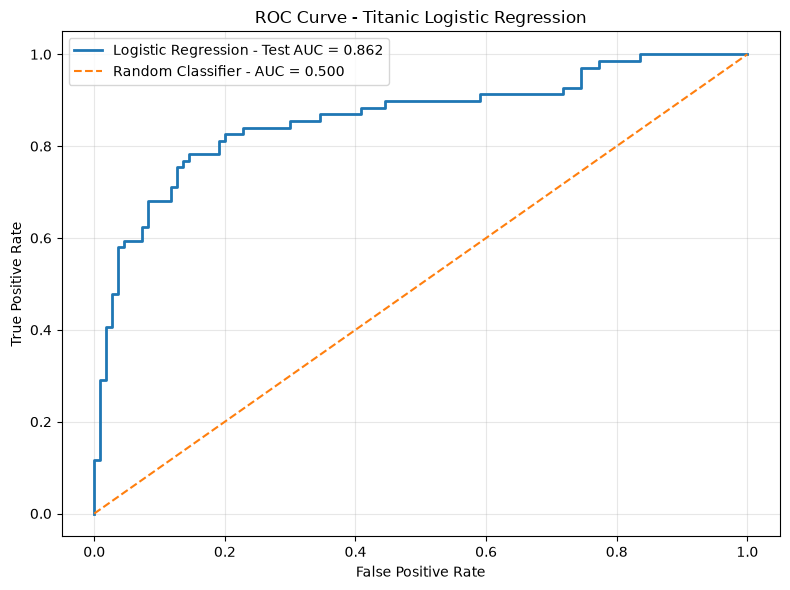

In [234]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Logistic Regression - Test AUC = {test_auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier - AUC = 0.500"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve - Titanic Logistic Regression"
)

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()



In [235]:

# ------------------------------------------------
# 27. WORKING DATA EXPORT
# ------------------------------------------------

working_data = X.copy()

working_data["Actual_Survived"] = y.values

# ------------------------------------------------
# 28. EXPORT EVERYTHING TO EXCEL
# ------------------------------------------------

output_file = "Titanic_Logistic_Regression_KFold_ROC_AUC.xlsx"

with pd.ExcelWriter(
    output_file,
    engine="openpyxl"
) as writer:

    # Original data
    df.to_excel(
        writer,
        sheet_name="Raw_Data",
        index=False
    )

    # Model-ready data
    working_data.to_excel(
        writer,
        sheet_name="Working_Data",
        index=False
    )

    # Coefficients
    coefficient_df.to_excel(
        writer,
        sheet_name="Coefficients",
        index=False
    )

    # Intercept
    intercept_df.to_excel(
        writer,
        sheet_name="Intercept",
        index=False
    )

    # Test predictions
    test_predictions.to_excel(
        writer,
        sheet_name="Test_Predictions",
        index=False
    )

    # Model evaluation
    model_evaluation.to_excel(
        writer,
        sheet_name="Model_Evaluation",
        index=False
    )

    # Confusion matrix
    confusion_matrix_df.to_excel(
        writer,
        sheet_name="Confusion_Matrix"
    )

    # TP / FP / FN / TN
    tp_fp_fn_tn.to_excel(
        writer,
        sheet_name="TP_FP_FN_TN",
        index=False
    )

    # K-Fold results
    kfold_results.to_excel(
        writer,
        sheet_name="KFold_Results",
        index=False
    )

    # K-Fold summary
    kfold_summary.to_excel(
        writer,
        sheet_name="KFold_Summary",
        index=False
    )

    # ROC curve coordinates
    roc_curve_df.to_excel(
        writer,
        sheet_name="ROC_Curve",
        index=False
    )

    # AUC summary
    auc_summary.to_excel(
        writer,
        sheet_name="AUC_Summary",
        index=False
    )

# ------------------------------------------------
# 29. FINAL MESSAGE
# ------------------------------------------------

print("\n" + "=" * 70)
print("PROCESS COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nExcel file created:")
print(output_file)

print("\nFinal Test Metrics:")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"Test AUC  : {test_auc:.4f}")

print("\n5-Fold Mean Metrics:")
print(f"Mean Accuracy : {cv_results['test_accuracy'].mean():.4f}")
print(f"Mean AUC      : {cv_results['test_roc_auc'].mean():.4f}")



PROCESS COMPLETED SUCCESSFULLY

Excel file created:
Titanic_Logistic_Regression_KFold_ROC_AUC.xlsx

Final Test Metrics:
Accuracy  : 0.8156
Precision : 0.8103
Recall    : 0.6812
F1 Score  : 0.7402
Test AUC  : 0.8619

5-Fold Mean Metrics:
Mean Accuracy : 0.8203
Mean AUC      : 0.8655


## Excel Output

The generated Excel workbook will contain:

| Sheet | Contents |
|---|---|
| Raw_Data | Original Titanic data |
| Working_Data | Cleaned/model-ready data |
| Coefficients | Logistic regression coefficients |
| Intercept | Model intercept |
| Test_Predictions | Actual, probability and predicted class |
| Model_Evaluation | Accuracy, Precision, Recall, F1 |
| Confusion_Matrix | 2 × 2 confusion matrix |
| TP_FP_FN_TN | Classification counts |
| KFold_Results | Accuracy and AUC for each fold |
| KFold_Summary | Mean and standard deviation |
| ROC_Curve | FPR, TPR and thresholds |
| AUC_Summary | Test AUC and CV AUC |

The ROC graph is also displayed directly in the notebook.